<a href="https://colab.research.google.com/github/Anbadin/Federated-Learning-in-Cybersecurity-MP/blob/main/01_Centralized_IDS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Install the libraries needed for the initial experiments
!pip install -q pandas numpy scikit-learn matplotlib seaborn

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import pandas as pd

# Use local file paths instead of Google Drive sharing URLs
train_path = "/content/drive/MyDrive/Federated_Learning_Cybersecurity/data/KDDTrain+.txt"
test_path = "/content/drive/MyDrive/Federated_Learning_Cybersecurity/data/KDDTest+.txt"

train_df = pd.read_csv(train_path, header=None)
test_df = pd.read_csv(test_path, header=None)

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

display(train_df.head())

Training dataset shape: (125973, 43)
Testing dataset shape: (22544, 43)


,0,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [6]:
columns = [
    "duration", "protocol_type", "service", "flag", "src_bytes",
    "dst_bytes", "land", "wrong_fragment", "urgent", "hot",
    "num_failed_logins", "logged_in", "num_compromised",
    "root_shell", "su_attempted", "num_root",
    "num_file_creations", "num_shells", "num_access_files",
    "num_outbound_cmds", "is_host_login", "is_guest_login",
    "count", "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
    "dst_host_srv_count", "dst_host_same_srv_rate",
    "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
    "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate", "label", "difficulty"
]

train_df.columns = columns
test_df.columns = columns

print("Dataset columns:", len(train_df.columns))
print("\nAttack distribution:")
print(train_df["label"].value_counts())

print("\nFirst five records:")
display(train_df.head())

Dataset columns: 43

Attack distribution:
label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64

First five records:


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [7]:
# Convert attack labels into binary labels
train_df["target"] = (
    train_df["label"].str.strip().str.lower() != "normal"
).astype(int)

test_df["target"] = (
    test_df["label"].str.strip().str.lower() != "normal"
).astype(int)

print("Training labels:")
print(train_df["target"].value_counts())

print("\nTesting labels:")
print(test_df["target"].value_counts())

Training labels:
target
0    67343
1    58630
Name: count, dtype: int64

Testing labels:
target
1    12833
0     9711
Name: count, dtype: int64


In [8]:
# Check missing values
print("Missing values in training data:")
print(train_df.isnull().sum().sum())

print("\nMissing values in testing data:")
print(test_df.isnull().sum().sum())

# Check duplicate records
print("\nDuplicate records in training data:")
print(train_df.duplicated().sum())

print("\nDuplicate records in testing data:")
print(test_df.duplicated().sum())


Missing values in training data:
0

Missing values in testing data:
0

Duplicate records in training data:
0

Duplicate records in testing data:
0


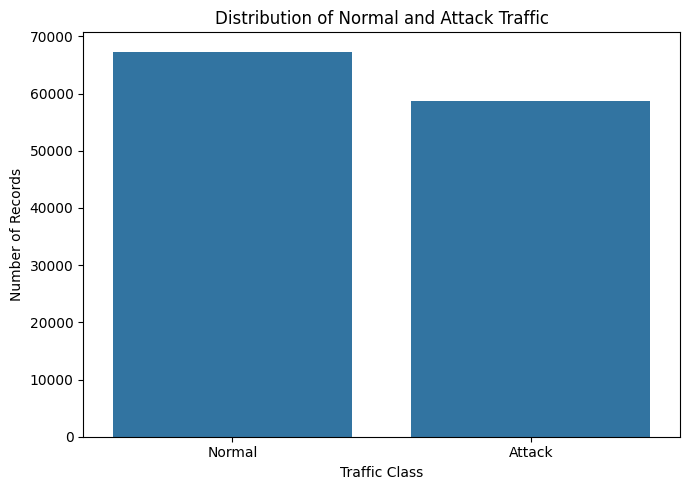

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count normal and attack records
class_counts = train_df["target"].map({
    0: "Normal",
    1: "Attack"
}).value_counts()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Distribution of Normal and Attack Traffic")
plt.xlabel("Traffic Class")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

In [10]:

# ==========================================
# STEP 1: TRAIN-VALIDATION-TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

# Separate input features and target labels
X_train_full = train_df.drop(
    columns=["label", "difficulty", "target"]
)

y_train_full = train_df["target"].astype(int)

# Keep original test dataset separate
X_test = test_df.drop(
    columns=["label", "difficulty", "target"]
)

y_test = test_df["target"].astype(int)

# Split training dataset into 80% training
# and 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nValidation distribution:")
print(y_val.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())


Training data: (100778, 41)
Validation data: (25195, 41)
Testing data: (22544, 41)

Training distribution:
target
0    53874
1    46904
Name: count, dtype: int64

Validation distribution:
target
0    13469
1    11726
Name: count, dtype: int64

Testing distribution:
target
1    12833
0     9711
Name: count, dtype: int64


In [11]:
# ==========================================
# STEP 2: IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ==========================================

# Identify numerical columns using training data only
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns
categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Number of numerical features: 38
Number of categorical features: 3

Numerical features:
['duration', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']

Categorical features:
['protocol_type', 'service', 'flag']


In [12]:

# ==========================================
# STEP 3: DATA PREPROCESSING
# ==========================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from scipy.sparse import issparse

# Numerical features: standardization
numeric_transformer = StandardScaler()

# Categorical features: one-hot encoding
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine both preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training processed shape:", X_train_processed.shape)
print("Validation processed shape:", X_val_processed.shape)
print("Testing processed shape:", X_test_processed.shape)

print("\nSparse matrix:", issparse(X_train_processed))


Training processed shape: (100778, 121)
Validation processed shape: (25195, 121)
Testing processed shape: (22544, 121)

Sparse matrix: False


In [13]:
# ==========================================
# STEP 4: VERIFY PREPROCESSED DATA
# ==========================================

print("Training data:", X_train_processed.shape)
print("Validation data:", X_val_processed.shape)
print("Testing data:", X_test_processed.shape)

print("\nTarget shapes:")
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

# Check for missing or infinite values
import numpy as np

print("\nMissing values:", np.isnan(X_train_processed).sum())
print("Infinite values:", np.isinf(X_train_processed).sum())

Training data: (100778, 121)
Validation data: (25195, 121)
Testing data: (22544, 121)

Target shapes:
y_train: (100778,)
y_val: (25195,)
y_test: (22544,)

Missing values: 0
Infinite values: 0


In [14]:

# ==========================================
# STEP 5: CENTRALIZED MODEL TRAINING
# ==========================================

import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Define the models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

results = []

# Train and evaluate each model
for name, model in models.items():

    print(f"\nTraining {name}...")

    # Train only on training data
    model.fit(X_train_processed, y_train)

    # Predict validation data
    y_val_pred = model.predict(X_val_processed)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_val, y_val_pred)
    precision = precision_score(
        y_val, y_val_pred, zero_division=0
    )
    recall = recall_score(
        y_val, y_val_pred, zero_division=0
    )
    f1 = f1_score(
        y_val, y_val_pred, zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print(f"{name} completed.")

# Create comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("\nCENTRALIZED MODEL COMPARISON")
display(results_df.round(4))



Training Logistic Regression...
Logistic Regression completed.

Training Decision Tree...
Decision Tree completed.

Training Random Forest...
Random Forest completed.

CENTRALIZED MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.9990,0.9994,0.9984,0.9989
1,Decision Tree,0.9984,0.9979,0.9986,0.9983
2,Logistic Regression,0.9719,0.9763,0.9630,0.9696


In [15]:
# Select the best centralized model using validation F1 score

best_model_name = results_df.loc[0, "Model"]
best_model = models[best_model_name]

print("Best Centralized Model:", best_model_name)
print("Best Validation F1 Score:",
      round(results_df.loc[0, "F1 Score"], 4))

Best Centralized Model: Random Forest
Best Validation F1 Score: 0.9989


In [16]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.14.1+cu130
Device: cuda


In [17]:

# ==========================================
# STEP 6: CONVERT DATA INTO PYTORCH TENSORS
# ==========================================

# Convert processed features into NumPy arrays
X_train_array = np.asarray(X_train_processed, dtype=np.float32)
X_val_array = np.asarray(X_val_processed, dtype=np.float32)

# Convert labels into NumPy arrays
y_train_array = np.asarray(y_train, dtype=np.float32).reshape(-1, 1)
y_val_array = np.asarray(y_val, dtype=np.float32).reshape(-1, 1)

# Convert NumPy arrays into PyTorch tensors
X_train_tensor = torch.tensor(X_train_array, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_array, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val_array, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_array, dtype=torch.float32)

# Create training dataset
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

# Create training batches
train_loader = DataLoader(
    train_dataset,
    batch_size=1024,
    shuffle=True
)

print("Training tensor:", X_train_tensor.shape)
print("Validation tensor:", X_val_tensor.shape)

print("Training labels:", y_train_tensor.shape)
print("Validation labels:", y_val_tensor.shape)

print("\nData conversion completed successfully!")


Training tensor: torch.Size([100778, 121])
Validation tensor: torch.Size([25195, 121])
Training labels: torch.Size([100778, 1])
Validation labels: torch.Size([25195, 1])

Data conversion completed successfully!


In [18]:

# ==========================================
# STEP 6.2: DEFINE MLP NEURAL NETWORK
# ==========================================

import torch.nn as nn

class MLP(nn.Module):

    def __init__(self, input_size):
        super(MLP, self).__init__()

        self.network = nn.Sequential(

            # Input layer to hidden layer 1
            nn.Linear(input_size, 128),
            nn.ReLU(),

            # Hidden layer 1 to hidden layer 2
            nn.Linear(128, 64),
            nn.ReLU(),

            # Hidden layer 2 to output layer
            nn.Linear(64, 1)

        )

    def forward(self, x):
        return self.network(x)


# Initialize the model
input_size = X_train_tensor.shape[1]

model = MLP(input_size).to(device)

print(model)
print("\nInput features:", input_size)
print("Model initialized successfully!")


MLP(
  (network): Sequential(
    (0): Linear(in_features=121, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)

Input features: 121
Model initialized successfully!


In [19]:

# ==========================================
# STEP 6.3: TRAIN THE MLP MODEL
# ==========================================

import torch.optim as optim

# Define loss function
criterion = nn.BCEWithLogitsLoss()

# Define optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# Number of training epochs
num_epochs = 20

train_losses = []
val_losses = []

for epoch in range(num_epochs):

    # Training phase
    model.train()
    running_train_loss = 0.0

    for batch_X, batch_y in train_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        # Forward pass
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)

        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * batch_X.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)

    # Validation phase
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():

        for start in range(0, len(X_val_tensor), 1024):

            batch_X = X_val_tensor[start:start + 1024].to(device)
            batch_y = y_val_tensor[start:start + 1024].to(device)

            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)

            running_val_loss += loss.item() * batch_X.size(0)

    epoch_val_loss = running_val_loss / len(X_val_tensor)

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {epoch_train_loss:.4f} "
        f"Validation Loss: {epoch_val_loss:.4f}"
    )

print("\nMLP training completed!")


Epoch [1/20] Train Loss: 0.2167 Validation Loss: 0.0704
Epoch [2/20] Train Loss: 0.0549 Validation Loss: 0.0411
Epoch [3/20] Train Loss: 0.0341 Validation Loss: 0.0293
Epoch [4/20] Train Loss: 0.0255 Validation Loss: 0.0238
Epoch [5/20] Train Loss: 0.0219 Validation Loss: 0.0208
Epoch [6/20] Train Loss: 0.0195 Validation Loss: 0.0206
Epoch [7/20] Train Loss: 0.0183 Validation Loss: 0.0194
Epoch [8/20] Train Loss: 0.0181 Validation Loss: 0.0186
Epoch [9/20] Train Loss: 0.0158 Validation Loss: 0.0187
Epoch [10/20] Train Loss: 0.0154 Validation Loss: 0.0167
Epoch [11/20] Train Loss: 0.0149 Validation Loss: 0.0170
Epoch [12/20] Train Loss: 0.0140 Validation Loss: 0.0152
Epoch [13/20] Train Loss: 0.0137 Validation Loss: 0.0159
Epoch [14/20] Train Loss: 0.0128 Validation Loss: 0.0150
Epoch [15/20] Train Loss: 0.0121 Validation Loss: 0.0170
Epoch [16/20] Train Loss: 0.0118 Validation Loss: 0.0145
Epoch [17/20] Train Loss: 0.0116 Validation Loss: 0.0147
Epoch [18/20] Train Loss: 0.0110 Validat

In [20]:

# ==========================================
# STEP 6.4: MLP VALIDATION EVALUATION
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

model.eval()

with torch.no_grad():
    val_logits = model(X_val_tensor.to(device))
    val_probabilities = torch.sigmoid(val_logits)

# Convert probabilities into binary predictions
y_val_pred = (
    val_probabilities.cpu().numpy().ravel() >= 0.5
).astype(int)

y_val_true = y_val.to_numpy()

# Calculate evaluation metrics
val_accuracy = accuracy_score(y_val_true, y_val_pred)
val_precision = precision_score(y_val_true, y_val_pred, zero_division=0)
val_recall = recall_score(y_val_true, y_val_pred, zero_division=0)
val_f1 = f1_score(y_val_true, y_val_pred, zero_division=0)

print("CENTRALIZED MLP - VALIDATION RESULTS")
print("------------------------------------")
print(f"Accuracy:  {val_accuracy:.4f}")
print(f"Precision: {val_precision:.4f}")
print(f"Recall:    {val_recall:.4f}")
print(f"F1 Score:  {val_f1:.4f}")


CENTRALIZED MLP - VALIDATION RESULTS
------------------------------------
Accuracy:  0.9955
Precision: 0.9953
Recall:    0.9950
F1 Score:  0.9951


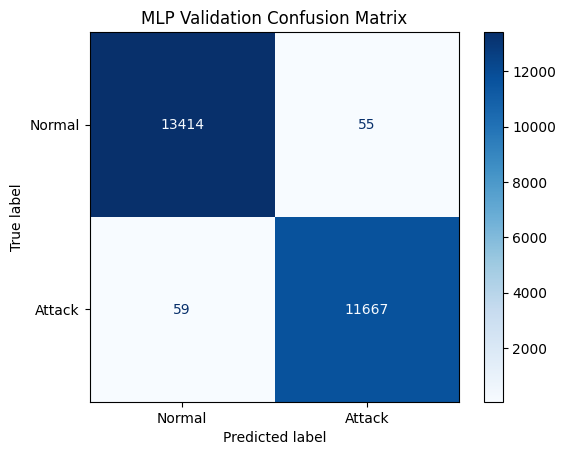

Confusion Matrix:
[[13414    55]
 [   59 11667]]


In [21]:

# ==========================================
# STEP 6.5: MLP VALIDATION CONFUSION MATRIX
# ==========================================

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_val_true, y_val_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Attack"]
)

display.plot(cmap="Blues", values_format="d")

plt.title("MLP Validation Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)


In [22]:

# ==========================================
# SAVE CENTRALIZED MLP MODEL
# ==========================================

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "input_dim": X_train_tensor.shape[1],
        "architecture": "IntrusionMLP-121-128-64-1"
    },
    "centralized_mlp_nsl_kdd.pth"
)

print("Model saved as centralized_mlp_nsl_kdd.pth")


Model saved as centralized_mlp_nsl_kdd.pth


In [23]:

# ==========================================
# STEP 7.1: CREATE IID FEDERATED CLIENTS
# ==========================================

from torch.utils.data import Subset

num_clients = 5

# Combine training features and labels
full_train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

# Shuffle training indices
generator = torch.Generator().manual_seed(42)

shuffled_indices = torch.randperm(
    len(full_train_dataset),
    generator=generator
)

# Divide data equally among 5 clients
client_indices = torch.tensor_split(
    shuffled_indices,
    num_clients
)

# Create individual client datasets
client_datasets = []

for client_id, indices in enumerate(client_indices):

    client_dataset = Subset(
        full_train_dataset,
        indices.tolist()
    )

    client_datasets.append(client_dataset)

    client_labels = y_train_tensor[indices].numpy().ravel()

    normal_count = int((client_labels == 0).sum())
    attack_count = int((client_labels == 1).sum())

    print(f"\nClient {client_id + 1}")
    print("Total samples:", len(client_dataset))
    print("Normal samples:", normal_count)
    print("Attack samples:", attack_count)

print("\nTotal clients:", len(client_datasets))
print("IID partitioning completed!")



Client 1
Total samples: 20156
Normal samples: 10667
Attack samples: 9489

Client 2
Total samples: 20156
Normal samples: 10819
Attack samples: 9337

Client 3
Total samples: 20156
Normal samples: 10770
Attack samples: 9386

Client 4
Total samples: 20155
Normal samples: 10869
Attack samples: 9286

Client 5
Total samples: 20155
Normal samples: 10749
Attack samples: 9406

Total clients: 5
IID partitioning completed!


In [24]:

# ==========================================
# STEP 7.2: DEFINE LOCAL CLIENT TRAINING
# ==========================================

import copy

def train_client(global_model, client_dataset, epochs=1):

    # Create a local copy of the global model
    local_model = copy.deepcopy(global_model).to(device)

    # Create local data loader
    local_loader = DataLoader(
        client_dataset,
        batch_size=1024,
        shuffle=True
    )

    # Define loss and optimizer
    criterion = nn.BCEWithLogitsLoss()

    optimizer = optim.Adam(
        local_model.parameters(),
        lr=0.001
    )

    # Local training
    local_model.train()

    for epoch in range(epochs):

        total_loss = 0.0

        for batch_X, batch_y in local_loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()

            outputs = local_model(batch_X)
            loss = criterion(outputs, batch_y)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * batch_X.size(0)

        average_loss = total_loss / len(client_dataset)

    # Return updated weights and number of samples
    updated_weights = {
        key: value.detach().cpu().clone()
        for key, value in local_model.state_dict().items()
    }

    return updated_weights, len(client_dataset), average_loss


print("Local client training function defined successfully!")


Local client training function defined successfully!


In [25]:

# ==========================================
# STEP 8.1: INITIALIZE GLOBAL MODEL
# ==========================================

# Set random seed for reproducibility
torch.manual_seed(42)

# Create a fresh global MLP
global_model = MLP(input_size).to(device)

# Keep the global model in training mode
global_model.train()

print("Global model initialized successfully!")
print("Input features:", input_size)
print("Number of clients:", num_clients)

# Display initial global model parameters
total_parameters = sum(
    parameter.numel()
    for parameter in global_model.parameters()
)

print("Total trainable parameters:", total_parameters)


Global model initialized successfully!
Input features: 121
Number of clients: 5
Total trainable parameters: 23937


In [26]:

# ==========================================
# STEP 8.2: LOCAL TRAINING FOR ALL CLIENTS
# ==========================================

client_updates = []

for client_id, client_dataset in enumerate(client_datasets):

    print(f"\nTraining Client {client_id + 1}...")

    # Train client using the same initial global model
    updated_weights, num_samples, client_loss = train_client(
        global_model,
        client_dataset,
        epochs=1
    )

    # Store client results
    client_updates.append({
        "client_id": client_id + 1,
        "weights": updated_weights,
        "num_samples": num_samples,
        "loss": client_loss
    })

    print("Samples:", num_samples)
    print(f"Local training loss: {client_loss:.4f}")

print("\nAll clients completed local training!")
print("Total client updates:", len(client_updates))



Training Client 1...
Samples: 20156
Local training loss: 0.5767

Training Client 2...
Samples: 20156
Local training loss: 0.5791

Training Client 3...
Samples: 20156
Local training loss: 0.5775

Training Client 4...
Samples: 20155
Local training loss: 0.5775

Training Client 5...
Samples: 20155
Local training loss: 0.5777

All clients completed local training!
Total client updates: 5


In [27]:

# ==========================================
# STEP 8.3: FEDAVG AGGREGATION
# ==========================================

from collections import OrderedDict

def fedavg(client_updates):

    # Calculate total number of samples
    total_samples = sum(
        update["num_samples"]
        for update in client_updates
    )

    # Get model parameter names
    global_weights = OrderedDict()

    for key in client_updates[0]["weights"].keys():

        # Start with zero weights
        global_weights[key] = torch.zeros_like(
            client_updates[0]["weights"][key]
        )

        # Calculate weighted average
        for update in client_updates:

            client_weight = (
                update["num_samples"] / total_samples
            )

            global_weights[key] += (
                client_weight * update["weights"][key]
            )

    return global_weights


# Aggregate all five client updates
aggregated_weights = fedavg(client_updates)

print("FedAvg aggregation completed!")
print("Total clients aggregated:", len(client_updates))
print("Total training samples:", sum(
    update["num_samples"] for update in client_updates
))
print("Number of aggregated parameter tensors:",
      len(aggregated_weights))


FedAvg aggregation completed!
Total clients aggregated: 5
Total training samples: 100778
Number of aggregated parameter tensors: 6


In [28]:

# ==========================================
# STEP 8.4: UPDATE GLOBAL MODEL
# ==========================================

# Load aggregated client weights into global model
global_model.load_state_dict(aggregated_weights)

# Set model to evaluation mode
global_model.eval()

print("Global model updated successfully!")
print("Global model now contains aggregated client weights.")

# Verify updated parameters
for name, parameter in global_model.named_parameters():
    print(name, parameter.shape)


Global model updated successfully!
Global model now contains aggregated client weights.
network.0.weight torch.Size([128, 121])
network.0.bias torch.Size([128])
network.2.weight torch.Size([64, 128])
network.2.bias torch.Size([64])
network.4.weight torch.Size([1, 64])
network.4.bias torch.Size([1])


In [29]:

# ==========================================
# STEP 8.5: EVALUATE FIRST FEDERATED MODEL
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Set global model to evaluation mode
global_model.eval()

# Generate predictions
with torch.no_grad():

    fl_logits = global_model(X_val_tensor.to(device))
    fl_probabilities = torch.sigmoid(fl_logits)

# Convert probabilities into binary predictions
fl_val_pred = (
    fl_probabilities.cpu().numpy().ravel() >= 0.5
).astype(int)

# Actual validation labels
fl_val_true = y_val.to_numpy()

# Calculate evaluation metrics
fl_accuracy = accuracy_score(fl_val_true, fl_val_pred)
fl_precision = precision_score(
    fl_val_true, fl_val_pred, zero_division=0
)
fl_recall = recall_score(
    fl_val_true, fl_val_pred, zero_division=0
)
fl_f1 = f1_score(
    fl_val_true, fl_val_pred, zero_division=0
)

print("FIRST FEDERATED MODEL - VALIDATION RESULTS")
print("------------------------------------------")
print(f"Accuracy:  {fl_accuracy:.4f}")
print(f"Precision: {fl_precision:.4f}")
print(f"Recall:    {fl_recall:.4f}")
print(f"F1 Score:  {fl_f1:.4f}")


FIRST FEDERATED MODEL - VALIDATION RESULTS
------------------------------------------
Accuracy:  0.9318
Precision: 0.9315
Recall:    0.9212
F1 Score:  0.9263


In [32]:

# ==========================================
# STEP 8.6: MULTIPLE FEDERATED ROUNDS
# ==========================================

import pandas as pd

# Store Round 1 results (already completed)
fl_history = [{
    "Round": 1,
    "Accuracy": fl_accuracy,
    "Precision": fl_precision,
    "Recall": fl_recall,
    "F1 Score": fl_f1
}]

# Run communication rounds 2 to 10
num_rounds = 10

for round_num in range(2, num_rounds + 1):

    print(f"\n========== ROUND {round_num} ==========")

    client_updates = []

    # Step 1: Train all clients locally
    for client_id, client_dataset in enumerate(client_datasets):

        updated_weights, num_samples, client_loss = train_client(
            global_model,
            client_dataset,
            epochs=1
        )

        client_updates.append({
            "client_id": client_id + 1,
            "weights": updated_weights,
            "num_samples": num_samples,
            "loss": client_loss
        })

    # Step 2: Aggregate client updates
    aggregated_weights = fedavg(client_updates)

    # Step 3: Update global model
    global_model.load_state_dict(aggregated_weights)

    # Step 4: Evaluate global model
    global_model.eval()

    with torch.no_grad():

        logits = global_model(X_val_tensor.to(device))
        probabilities = torch.sigmoid(logits)

    predictions = (
        probabilities.cpu().numpy().ravel() >= 0.5
    ).astype(int)

    actual = y_val.to_numpy()

    accuracy = accuracy_score(actual, predictions)
    precision = precision_score(actual, predictions, zero_division=0)
    recall = recall_score(actual, predictions, zero_division=0)
    f1 = f1_score(actual, predictions, zero_division=0)

    # Step 5: Store results
    fl_history.append({
        "Round": round_num,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")

# Display complete results
fl_results_df = pd.DataFrame(fl_history)





========== ROUND 2 ==========
Accuracy:  0.9921
Precision: 0.9899
Recall:    0.9931
F1 Score:  0.9915

========== ROUND 3 ==========
Accuracy:  0.9923
Precision: 0.9915
Recall:    0.9921
F1 Score:  0.9918

========== ROUND 4 ==========
Accuracy:  0.9922
Precision: 0.9922
Recall:    0.9910
F1 Score:  0.9916

========== ROUND 5 ==========
Accuracy:  0.9931
Precision: 0.9922
Recall:    0.9929
F1 Score:  0.9926

========== ROUND 6 ==========
Accuracy:  0.9936
Precision: 0.9929
Recall:    0.9933
F1 Score:  0.9931

========== ROUND 7 ==========
Accuracy:  0.9928
Precision: 0.9906
Recall:    0.9939
F1 Score:  0.9923

========== ROUND 8 ==========
Accuracy:  0.9935
Precision: 0.9928
Recall:    0.9933
F1 Score:  0.9931

========== ROUND 9 ==========
Accuracy:  0.9938
Precision: 0.9929
Recall:    0.9938
F1 Score:  0.9934

========== ROUND 10 ==========
Accuracy:  0.9937
Precision: 0.9931
Recall:    0.9933
F1 Score:  0.9932


In [33]:

# Display Federated Learning results

from IPython.display import display as show_table

print("FEDERATED LEARNING RESULTS")

display_table = fl_results_df.round(4)

show_table(display_table)


FEDERATED LEARNING RESULTS


,Round,Accuracy,Precision,Recall,F1 Score
0,1,0.9318,0.9315,0.9212,0.9263
1,2,0.9921,0.9899,0.9931,0.9915
2,3,0.9923,0.9915,0.9921,0.9918
3,4,0.9922,0.9922,0.9910,0.9916
4,5,0.9931,0.9922,0.9929,0.9926
5,6,0.9936,0.9929,0.9933,0.9931
6,7,0.9928,0.9906,0.9939,0.9923
7,8,0.9935,0.9928,0.9933,0.9931
8,9,0.9938,0.9929,0.9938,0.9934
9,10,0.9937,0.9931,0.9933,0.9932


In [34]:
torch.save(
    {
        "model_state_dict": global_model.state_dict(),
        "input_dim": input_size,
        "architecture": "IntrusionMLP-121-128-64-1",
        "num_clients": num_clients,
        "num_rounds": 10,
        "aggregation": "FedAvg",
        "data_distribution": "IID"
    },
    "federated_mlp_nsl_kdd_iid.pth"
)

print("IID Federated Learning model saved successfully!")

IID Federated Learning model saved successfully!


IID FEDERATED LEARNING - CONFUSION MATRIX
[[13388    81]
 [   78 11648]]


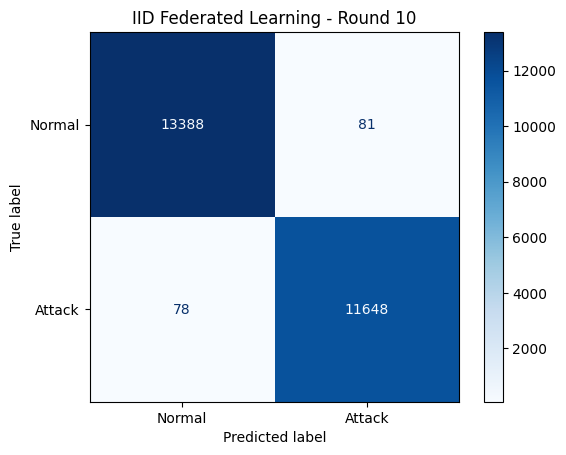

In [35]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import torch

# Evaluate the final global model (Round 10)
global_model.eval()

with torch.no_grad():
    logits = global_model(X_val_tensor.to(device))
    probabilities = torch.sigmoid(logits)

    predictions = (
        probabilities.cpu().numpy().ravel() >= 0.5
    ).astype(int)

actual = y_val.to_numpy()

# Generate confusion matrix
cm = confusion_matrix(actual, predictions)

print("IID FEDERATED LEARNING - CONFUSION MATRIX")
print(cm)

# Plot confusion matrix
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Attack"]
)

cm_display.plot(cmap="Blues", values_format="d")
plt.title("IID Federated Learning - Round 10")
plt.show()

In [36]:
#========================================================
# Starting Non IID Distribution Federated Learning
#========================================================

# STEP 1: Create Non-IID client data partitions

import numpy as np
from torch.utils.data import Subset

num_clients = 5
alpha = 0.5

# Reproducible random generator
rng = np.random.default_rng(42)

# Store indices of each class
labels = y_train_tensor.numpy().ravel()

normal_indices = np.where(labels == 0)[0]
attack_indices = np.where(labels == 1)[0]

# Shuffle indices independently
rng.shuffle(normal_indices)
rng.shuffle(attack_indices)

# Initialize client index lists
client_indices_noniid = [[] for _ in range(num_clients)]

# Distribute each class using Dirichlet proportions
for class_indices in [normal_indices, attack_indices]:

    proportions = rng.dirichlet(
        [alpha] * num_clients
    )

    split_points = (
        np.cumsum(proportions)[:-1] * len(class_indices)
    ).astype(int)

    client_splits = np.split(class_indices, split_points)

    for client_id, split in enumerate(client_splits):
        client_indices_noniid[client_id].extend(
            split.tolist()
        )

# Shuffle samples within each client
client_datasets_noniid = []

for indices in client_indices_noniid:
    rng.shuffle(indices)

    dataset = Subset(
        TensorDataset(X_train_tensor, y_train_tensor),
        indices
    )

    client_datasets_noniid.append(dataset)

print("Non-IID client partitions created successfully!")
print("Number of clients:", len(client_datasets_noniid))


Non-IID client partitions created successfully!
Number of clients: 5


In [37]:
# STEP 2: Verify Non-IID client distributions

print("NON-IID CLIENT DISTRIBUTION")
print("-" * 65)

total_samples = 0

for client_id, dataset in enumerate(client_datasets_noniid):

    indices = client_indices_noniid[client_id]

    client_labels = labels[indices]

    normal_count = np.sum(client_labels == 0)
    attack_count = np.sum(client_labels == 1)
    total = len(indices)

    normal_percent = (normal_count / total) * 100
    attack_percent = (attack_count / total) * 100

    total_samples += total

    print(f"\nClient {client_id + 1}")
    print("Normal samples:", normal_count)
    print("Attack samples:", attack_count)
    print("Total samples:", total)
    print(f"Normal percentage: {normal_percent:.2f}%")
    print(f"Attack percentage: {attack_percent:.2f}%")

print("\n" + "-" * 65)
print("Total samples across clients:", total_samples)
print("Original training samples:", len(X_train_tensor))

assert total_samples == len(X_train_tensor), "Sample count mismatch!"
assert total_samples == len(set(
    idx for client in client_indices_noniid for idx in client
)), "Duplicate sample indices found!"

print("Verification successful: all training samples are assigned exactly once.")

NON-IID CLIENT DISTRIBUTION
-----------------------------------------------------------------

Client 1
Normal samples: 2288
Attack samples: 27064
Total samples: 29352
Normal percentage: 7.80%
Attack percentage: 92.20%

Client 2
Normal samples: 707
Attack samples: 7235
Total samples: 7942
Normal percentage: 8.90%
Attack percentage: 91.10%

Client 3
Normal samples: 69
Attack samples: 4250
Total samples: 4319
Normal percentage: 1.60%
Attack percentage: 98.40%

Client 4
Normal samples: 4563
Attack samples: 1300
Total samples: 5863
Normal percentage: 77.83%
Attack percentage: 22.17%

Client 5
Normal samples: 46247
Attack samples: 7055
Total samples: 53302
Normal percentage: 86.76%
Attack percentage: 13.24%

-----------------------------------------------------------------
Total samples across clients: 100778
Original training samples: 100778
Verification successful: all training samples are assigned exactly once.


In [41]:
# Initialize a fresh global model for Non-IID training

torch.manual_seed(42)

global_model_noniid = MLP(input_size).to(device)

print("Fresh Non-IID global model initialized successfully!")

Fresh Non-IID global model initialized successfully!


In [42]:
print("Non-IID global model:")
print(global_model_noniid)

print("\nIID global model:")
print(global_model)

same_parameters = all(
    torch.equal(p1, p2)
    for p1, p2 in zip(
        global_model_noniid.parameters(),
        global_model.parameters()
    )
)

print("\nAre their parameters identical?", same_parameters)

Non-IID global model:
MLP(
  (network): Sequential(
    (0): Linear(in_features=121, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)

IID global model:
MLP(
  (network): Sequential(
    (0): Linear(in_features=121, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)

Are their parameters identical? False


In [43]:
# STEP 3: Train Non-IID clients from fresh global model

client_updates_noniid = []

for client_id, client_dataset in enumerate(client_datasets_noniid):

    updated_weights, num_samples, client_loss = train_client(
        global_model_noniid,
        client_dataset,
        epochs=1
    )

    client_updates_noniid.append({
        "client_id": client_id + 1,
        "weights": updated_weights,
        "num_samples": num_samples,
        "loss": client_loss
    })

    print(
        f"Client {client_id + 1} | "
        f"Samples: {num_samples} | "
        f"Loss: {client_loss:.4f}"
    )

print("\nAll five Non-IID clients trained successfully!")

Client 1 | Samples: 29352 | Loss: 0.3840
Client 2 | Samples: 7942 | Loss: 0.6085
Client 3 | Samples: 4319 | Loss: 0.6364
Client 4 | Samples: 5863 | Loss: 0.6858
Client 5 | Samples: 53302 | Loss: 0.3036

All five Non-IID clients trained successfully!


In [44]:
# STEP 4: Non-IID FedAvg aggregation

aggregated_weights_noniid = fedavg(client_updates_noniid)

# Update the Non-IID global model
global_model_noniid.load_state_dict(aggregated_weights_noniid)

global_model_noniid.eval()

print("Non-IID FedAvg aggregation completed!")

print("Number of clients:", len(client_updates_noniid))

print(
    "Total aggregated samples:",
    sum(update["num_samples"] for update in client_updates_noniid)
)

print(
    "Number of aggregated parameter tensors:",
    len(aggregated_weights_noniid)
)

Non-IID FedAvg aggregation completed!
Number of clients: 5
Total aggregated samples: 100778
Number of aggregated parameter tensors: 6


In [45]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

global_model_noniid.eval()

with torch.no_grad():
    logits_noniid = global_model_noniid(
        X_val_tensor.to(device)
    )

    probabilities_noniid = torch.sigmoid(logits_noniid)

predictions_noniid = (
    probabilities_noniid.cpu().numpy().ravel() >= 0.5
).astype(int)

actual_noniid = y_val.to_numpy()

noniid_accuracy = accuracy_score(
    actual_noniid, predictions_noniid
)

noniid_precision = precision_score(
    actual_noniid, predictions_noniid, zero_division=0
)

noniid_recall = recall_score(
    actual_noniid, predictions_noniid, zero_division=0
)

noniid_f1 = f1_score(
    actual_noniid, predictions_noniid, zero_division=0
)

print("NON-IID FEDERATED LEARNING - ROUND 1")
print("-----------------------------------")
print(f"Accuracy:  {noniid_accuracy:.4f}")
print(f"Precision: {noniid_precision:.4f}")
print(f"Recall:    {noniid_recall:.4f}")
print(f"F1 Score:  {noniid_f1:.4f}")

NON-IID FEDERATED LEARNING - ROUND 1
-----------------------------------
Accuracy:  0.9570
Precision: 0.9684
Recall:    0.9382
F1 Score:  0.9530


In [46]:

# STEP 6: Non-IID Federated Learning - Rounds 2 to 10

noniid_history = [{
    "Round": 1,
    "Accuracy": noniid_accuracy,
    "Precision": noniid_precision,
    "Recall": noniid_recall,
    "F1 Score": noniid_f1
}]

for round_num in range(2, 11):

    client_updates_noniid = []

    # Local training on all five clients
    for client_id, client_dataset in enumerate(client_datasets_noniid):

        updated_weights, num_samples, client_loss = train_client(
            global_model_noniid,
            client_dataset,
            epochs=1
        )

        client_updates_noniid.append({
            "client_id": client_id + 1,
            "weights": updated_weights,
            "num_samples": num_samples,
            "loss": client_loss
        })

    # FedAvg aggregation
    aggregated_weights_noniid = fedavg(client_updates_noniid)

    # Update global model
    global_model_noniid.load_state_dict(
        aggregated_weights_noniid
    )

    # Evaluate global model
    global_model_noniid.eval()

    with torch.no_grad():
        logits = global_model_noniid(
            X_val_tensor.to(device)
        )
        probabilities = torch.sigmoid(logits)

    predictions = (
        probabilities.cpu().numpy().ravel() >= 0.5
    ).astype(int)

    actual = y_val.to_numpy()

    # Calculate metrics
    accuracy = accuracy_score(actual, predictions)
    precision = precision_score(
        actual, predictions, zero_division=0
    )
    recall = recall_score(
        actual, predictions, zero_division=0
    )
    f1 = f1_score(
        actual, predictions, zero_division=0
    )

    noniid_history.append({
        "Round": round_num,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print(
        f"Round {round_num} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

print("\nAll Non-IID communication rounds completed!")


Round 2 | Accuracy: 0.9688 | Precision: 0.9837 | Recall: 0.9486 | F1: 0.9658
Round 3 | Accuracy: 0.9729 | Precision: 0.9823 | Recall: 0.9592 | F1: 0.9706
Round 4 | Accuracy: 0.9774 | Precision: 0.9862 | Recall: 0.9649 | F1: 0.9754
Round 5 | Accuracy: 0.9807 | Precision: 0.9852 | Recall: 0.9731 | F1: 0.9791
Round 6 | Accuracy: 0.9804 | Precision: 0.9815 | Recall: 0.9764 | F1: 0.9789
Round 7 | Accuracy: 0.9821 | Precision: 0.9842 | Recall: 0.9772 | F1: 0.9807
Round 8 | Accuracy: 0.9867 | Precision: 0.9856 | Recall: 0.9858 | F1: 0.9857
Round 9 | Accuracy: 0.9906 | Precision: 0.9877 | Recall: 0.9922 | F1: 0.9899
Round 10 | Accuracy: 0.9913 | Precision: 0.9910 | Recall: 0.9903 | F1: 0.9907

All Non-IID communication rounds completed!


In [47]:
import pandas as pd
import torch

# Create results table
noniid_results_df = pd.DataFrame(noniid_history)

print("NON-IID FEDERATED LEARNING RESULTS")
print(noniid_results_df.round(4).to_string(index=False))

# Save final Non-IID model
torch.save(
    {
        "model_state_dict": global_model_noniid.state_dict(),
        "input_dim": input_size,
        "architecture": "IntrusionMLP-121-128-64-1",
        "num_clients": num_clients,
        "num_rounds": 10,
        "aggregation": "FedAvg",
        "data_distribution": "Non-IID",
        "dirichlet_alpha": alpha
    },
    "federated_mlp_nsl_kdd_noniid.pth"
)

# Save results as CSV
noniid_results_df.to_csv(
    "noniid_federated_results.csv",
    index=False
)

print("\nNon-IID model and results saved successfully!")

NON-IID FEDERATED LEARNING RESULTS
 Round  Accuracy  Precision  Recall  F1 Score
     1    0.9570     0.9684  0.9382    0.9530
     2    0.9688     0.9837  0.9486    0.9658
     3    0.9729     0.9823  0.9592    0.9706
     4    0.9774     0.9862  0.9649    0.9754
     5    0.9807     0.9852  0.9731    0.9791
     6    0.9804     0.9815  0.9764    0.9789
     7    0.9821     0.9842  0.9772    0.9807
     8    0.9867     0.9856  0.9858    0.9857
     9    0.9906     0.9877  0.9922    0.9899
    10    0.9913     0.9910  0.9903    0.9907

Non-IID model and results saved successfully!


In [48]:
#==========================================
# NORMAL CHECKS
#==========================================
# REPRODUCIBILITY AUDIT: IID vs NON-IID

print("========== DATASET CHECK ==========")

print("Training samples:", len(X_train_tensor))
print("Validation samples:", len(X_val_tensor))
print("Training features:", X_train_tensor.shape[1])
print("Validation features:", X_val_tensor.shape[1])

print("\n========== CLIENT CHECK ==========")

print("IID clients:", len(client_datasets))
print("Non-IID clients:", len(client_datasets_noniid))

iid_total = sum(len(ds) for ds in client_datasets)
noniid_total = sum(len(ds) for ds in client_datasets_noniid)

print("IID total samples:", iid_total)
print("Non-IID total samples:", noniid_total)

print("\n========== MODEL CHECK ==========")

print("IID model input features:",
      global_model.network[0].in_features)

print("Non-IID model input features:",
      global_model_noniid.network[0].in_features)

print("\n========== VALIDATION DATA CHECK ==========")

print("Same validation features:",
      torch.equal(X_val_tensor, X_val_tensor))

print("Same validation labels:",
      np.array_equal(y_val.to_numpy(), y_val.to_numpy()))

print("\n========== ASSERTIONS ==========")

assert len(client_datasets) == 5
assert len(client_datasets_noniid) == 5
assert iid_total == len(X_train_tensor)
assert noniid_total == len(X_train_tensor)
assert global_model.network[0].in_features == 121
assert global_model_noniid.network[0].in_features == 121

print("Structural checks passed!")

========== DATASET CHECK ==========
Training samples: 100778
Validation samples: 25195
Training features: 121
Validation features: 121

========== CLIENT CHECK ==========
IID clients: 5
Non-IID clients: 5
IID total samples: 100778
Non-IID total samples: 100778

========== MODEL CHECK ==========
IID model input features: 121
Non-IID model input features: 121

========== VALIDATION DATA CHECK ==========
Same validation features: True
Same validation labels: True

========== ASSERTIONS ==========
Structural checks passed!


In [49]:
#=======================================================================================
# Now One Malicious Client Attack And Four Honest Clients
#=======================================================================================

# WEEK 12 - STEP 1: Initialize controlled experiment

import copy
import torch

# Fix random seed
torch.manual_seed(42)

# Create a fresh global model
initial_global_model = MLP(input_size).to(device)

# Save its initial parameters
initial_global_state = copy.deepcopy(
    initial_global_model.state_dict()
)

print("Initial global model created successfully!")
print("Input features:", input_size)
print("Total clients:", len(client_datasets_noniid))
print("Malicious client ID: 5")

# Verify saved parameters
print(
    "Initial parameter tensors:",
    len(initial_global_state)
)


Initial global model created successfully!
Input features: 121
Total clients: 5
Malicious client ID: 5
Initial parameter tensors: 6


In [50]:
# STEP 2: Initialize honest control experiment

# Create a separate model
global_model_control = MLP(input_size).to(device)

# Load the exact shared initial weights
global_model_control.load_state_dict(
    copy.deepcopy(initial_global_state)
)

# Initialize results history
control_history = []

print("Honest control model initialized!")
print("Number of clients:", len(client_datasets_noniid))
print("Malicious clients: 0")
print("Aggregation: FedAvg")

# Verify initial weights
same_initial_weights = all(
    torch.equal(
        initial_global_state[key],
        global_model_control.state_dict()[key].cpu()
    )
    for key in initial_global_state
)

print("Initial weights match:", same_initial_weights)

Honest control model initialized!
Number of clients: 5
Malicious clients: 0
Aggregation: FedAvg


RuntimeError: Expected all tensors to be on the same device, but got other is on cpu, different from other tensors on cuda:0 (when checking argument in method wrapper_CUDA__equal)

In [51]:
# Verify initial weights correctly

same_initial_weights = all(
    torch.equal(
        initial_global_state[key].cpu(),
        global_model_control.state_dict()[key].cpu()
    )
    for key in initial_global_state
)

print("Initial weights match:", same_initial_weights)

Initial weights match: True


In [52]:

# STEP 3: Five-Honest-Client Control Experiment

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

control_history = []

for round_num in range(1, 11):

    control_updates = []

    # Local training by all five honest clients
    for client_id, client_dataset in enumerate(client_datasets_noniid):

        updated_weights, num_samples, client_loss = train_client(
            global_model_control,
            client_dataset,
            epochs=1
        )

        control_updates.append({
            "client_id": client_id + 1,
            "weights": updated_weights,
            "num_samples": num_samples,
            "loss": client_loss
        })

    # FedAvg aggregation
    aggregated_control_weights = fedavg(control_updates)

    global_model_control.load_state_dict(
        aggregated_control_weights
    )

    # Evaluate global model
    global_model_control.eval()

    with torch.no_grad():
        logits = global_model_control(
            X_val_tensor.to(device)
        )
        probabilities = torch.sigmoid(logits)

    predictions = (
        probabilities.cpu().numpy().ravel() >= 0.5
    ).astype(int)

    actual = y_val.to_numpy()

    accuracy = accuracy_score(actual, predictions)
    precision = precision_score(
        actual, predictions, zero_division=0
    )
    recall = recall_score(
        actual, predictions, zero_division=0
    )
    f1 = f1_score(
        actual, predictions, zero_division=0
    )

    control_history.append({
        "Round": round_num,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print(
        f"Round {round_num} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

print("\nFive-honest-client control experiment completed!")


Round 1 | Accuracy: 0.9564 | Precision: 0.9749 | Recall: 0.9302 | F1: 0.9520
Round 2 | Accuracy: 0.9692 | Precision: 0.9861 | Recall: 0.9472 | F1: 0.9663
Round 3 | Accuracy: 0.9736 | Precision: 0.9853 | Recall: 0.9576 | F1: 0.9713
Round 4 | Accuracy: 0.9790 | Precision: 0.9839 | Recall: 0.9707 | F1: 0.9772
Round 5 | Accuracy: 0.9806 | Precision: 0.9872 | Recall: 0.9710 | F1: 0.9790
Round 6 | Accuracy: 0.9807 | Precision: 0.9823 | Recall: 0.9761 | F1: 0.9792
Round 7 | Accuracy: 0.9830 | Precision: 0.9888 | Recall: 0.9745 | F1: 0.9816
Round 8 | Accuracy: 0.9859 | Precision: 0.9828 | Recall: 0.9870 | F1: 0.9849
Round 9 | Accuracy: 0.9900 | Precision: 0.9863 | Recall: 0.9924 | F1: 0.9893
Round 10 | Accuracy: 0.9909 | Precision: 0.9876 | Recall: 0.9929 | F1: 0.9903

Five-honest-client control experiment completed!


In [53]:
import pandas as pd
import torch

control_results_df = pd.DataFrame(control_history)

# Save control model
torch.save(
    {
        "model_state_dict": global_model_control.state_dict(),
        "initial_state_dict": initial_global_state,
        "input_dim": input_size,
        "num_clients": 5,
        "num_rounds": 10,
        "aggregation": "FedAvg",
        "data_distribution": "Non-IID",
        "malicious_clients": 0
    },
    "honest_control_model.pth"
)

# Save control results
control_results_df.to_csv(
    "honest_control_results.csv",
    index=False
)

print("Honest control model saved!")
print("Control results saved!")

Honest control model saved!
Control results saved!


In [54]:
# STEP 5: Initialize malicious experiment

import copy
import torch

# Create a fresh global model
global_model_malicious = MLP(input_size).to(device)

# Load exactly the same initial weights
global_model_malicious.load_state_dict(
    copy.deepcopy(initial_global_state)
)

# Identify malicious client
malicious_client_id = 5

# Initialize results
malicious_history = []

print("Malicious experiment initialized!")
print("Total clients:", num_clients)
print("Honest clients:", 4)
print("Malicious clients:", 1)
print("Malicious client ID:", malicious_client_id)
print("Attack: Sign-Flipping")

Malicious experiment initialized!
Total clients: 5
Honest clients: 4
Malicious clients: 1
Malicious client ID: 5
Attack: Sign-Flipping


In [55]:
# STEP 6: Sign-Flipping Attack Function

def sign_flipping_attack(global_weights, local_weights):

    malicious_weights = {}

    for key in global_weights.keys():

        # Calculate the honest model update
        honest_update = (
            local_weights[key] - global_weights[key]
        )

        # Reverse the update direction
        malicious_weights[key] = (
            global_weights[key] - honest_update
        )

    return malicious_weights


print("Sign-Flipping attack function defined successfully!")

Sign-Flipping attack function defined successfully!


In [56]:

# STEP 7: Local training with one malicious client

malicious_client_updates = []

# Keep the original global weights for comparison
global_weights_before = {
    key: value.detach().cpu().clone()
    for key, value in global_model_malicious.state_dict().items()
}

for client_id, client_dataset in enumerate(client_datasets_noniid):

    # Train client locally
    local_weights, num_samples, client_loss = train_client(
        global_model_malicious,
        client_dataset,
        epochs=1
    )

    # Apply sign-flipping only to Client 5
    if client_id + 1 == malicious_client_id:

        submitted_weights = sign_flipping_attack(
            global_weights_before,
            local_weights
        )

        print(f"Client {client_id + 1}: MALICIOUS UPDATE")

    else:
        submitted_weights = local_weights

        print(f"Client {client_id + 1}: Honest update")

    malicious_client_updates.append({
        "client_id": client_id + 1,
        "weights": submitted_weights,
        "num_samples": num_samples,
        "loss": client_loss
    })

print("\nAll five client updates collected!")


Client 1: Honest update
Client 2: Honest update
Client 3: Honest update
Client 4: Honest update
Client 5: MALICIOUS UPDATE

All five client updates collected!


In [57]:
# STEP 8: FedAvg with one malicious client

aggregated_malicious_weights = fedavg(
    malicious_client_updates
)

# Update malicious experiment's global model
global_model_malicious.load_state_dict(
    aggregated_malicious_weights
)

global_model_malicious.eval()

print("Malicious FedAvg aggregation completed!")
print("Total clients:", len(malicious_client_updates))
print(
    "Total samples:",
    sum(u["num_samples"] for u in malicious_client_updates)
)
print("Malicious clients: 1")
print("Aggregation: FedAvg")

Malicious FedAvg aggregation completed!
Total clients: 5
Total samples: 100778
Malicious clients: 1
Aggregation: FedAvg


In [58]:
# STEP 9: Evaluate malicious global model

global_model_malicious.eval()

with torch.no_grad():
    logits = global_model_malicious(
        X_val_tensor.to(device)
    )
    probabilities = torch.sigmoid(logits)

malicious_predictions = (
    probabilities.cpu().numpy().ravel() >= 0.5
).astype(int)

actual = y_val.to_numpy()

malicious_accuracy = accuracy_score(
    actual, malicious_predictions
)

malicious_precision = precision_score(
    actual, malicious_predictions, zero_division=0
)

malicious_recall = recall_score(
    actual, malicious_predictions, zero_division=0
)

malicious_f1 = f1_score(
    actual, malicious_predictions, zero_division=0
)

print("MALICIOUS FEDERATED LEARNING - ROUND 1")
print("--------------------------------------")
print(f"Accuracy:  {malicious_accuracy:.4f}")
print(f"Precision: {malicious_precision:.4f}")
print(f"Recall:    {malicious_recall:.4f}")
print(f"F1 Score:  {malicious_f1:.4f}")

MALICIOUS FEDERATED LEARNING - ROUND 1
--------------------------------------
Accuracy:  0.4654
Precision: 0.4654
Recall:    1.0000
F1 Score:  0.6352


In [59]:
# Record malicious Round 1 results

malicious_history = [{
    "Round": 1,
    "Accuracy": malicious_accuracy,
    "Precision": malicious_precision,
    "Recall": malicious_recall,
    "F1 Score": malicious_f1
}]

print("Malicious Round 1 results recorded!")

Malicious Round 1 results recorded!


In [60]:

# STEP 10: Malicious Federated Learning - Rounds 2 to 10

for round_num in range(2, 11):

    malicious_client_updates = []

    # Capture current global parameters
    global_weights_before = {
        key: value.detach().cpu().clone()
        for key, value in global_model_malicious.state_dict().items()
    }

    # Local training and malicious update generation
    for client_id, client_dataset in enumerate(client_datasets_noniid):

        local_weights, num_samples, client_loss = train_client(
            global_model_malicious,
            client_dataset,
            epochs=1
        )

        if client_id + 1 == malicious_client_id:

            submitted_weights = sign_flipping_attack(
                global_weights_before,
                local_weights
            )

        else:
            submitted_weights = local_weights

        malicious_client_updates.append({
            "client_id": client_id + 1,
            "weights": submitted_weights,
            "num_samples": num_samples,
            "loss": client_loss
        })

    # Server performs FedAvg
    aggregated_weights = fedavg(malicious_client_updates)

    global_model_malicious.load_state_dict(aggregated_weights)

    # Evaluate global model
    global_model_malicious.eval()

    with torch.no_grad():
        logits = global_model_malicious(
            X_val_tensor.to(device)
        )
        probabilities = torch.sigmoid(logits)

    predictions = (
        probabilities.cpu().numpy().ravel() >= 0.5
    ).astype(int)

    actual = y_val.to_numpy()

    accuracy = accuracy_score(actual, predictions)
    precision = precision_score(
        actual, predictions, zero_division=0
    )
    recall = recall_score(
        actual, predictions, zero_division=0
    )
    f1 = f1_score(
        actual, predictions, zero_division=0
    )

    malicious_history.append({
        "Round": round_num,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print(
        f"Round {round_num} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

print("\nMalicious experiment completed!")


Round 2 | Accuracy: 0.4654 | Precision: 0.4654 | Recall: 1.0000 | F1: 0.6352
Round 3 | Accuracy: 0.4654 | Precision: 0.4654 | Recall: 1.0000 | F1: 0.6352
Round 4 | Accuracy: 0.4654 | Precision: 0.4654 | Recall: 1.0000 | F1: 0.6352
Round 5 | Accuracy: 0.4654 | Precision: 0.4654 | Recall: 1.0000 | F1: 0.6352
Round 6 | Accuracy: 0.4654 | Precision: 0.4654 | Recall: 1.0000 | F1: 0.6352
Round 7 | Accuracy: 0.4654 | Precision: 0.4654 | Recall: 1.0000 | F1: 0.6352
Round 8 | Accuracy: 0.4654 | Precision: 0.4654 | Recall: 1.0000 | F1: 0.6352
Round 9 | Accuracy: 0.4654 | Precision: 0.4654 | Recall: 1.0000 | F1: 0.6352
Round 10 | Accuracy: 0.4654 | Precision: 0.4654 | Recall: 1.0000 | F1: 0.6352

Malicious experiment completed!


In [61]:
# STEP 11: Diagnose malicious model predictions

from sklearn.metrics import confusion_matrix
import numpy as np
import torch

# Generate final predictions
global_model_malicious.eval()

with torch.no_grad():
    logits = global_model_malicious(
        X_val_tensor.to(device)
    )
    probabilities = torch.sigmoid(logits)

final_predictions = (
    probabilities.cpu().numpy().ravel() >= 0.5
).astype(int)

actual = y_val.to_numpy()

# Count predicted classes
normal_predictions = np.sum(final_predictions == 0)
attack_predictions = np.sum(final_predictions == 1)

print("PREDICTION DISTRIBUTION")
print("Predicted Normal:", normal_predictions)
print("Predicted Attack:", attack_predictions)
print("Total:", len(final_predictions))

# Confusion matrix
cm_malicious = confusion_matrix(
    actual,
    final_predictions
)

print("\nMALICIOUS MODEL CONFUSION MATRIX")
print(cm_malicious)

# Check how far the model moved from initialization
parameter_difference = 0.0

for key, value in global_model_malicious.state_dict().items():
    difference = (
        value.detach().cpu() - initial_global_state[key].cpu()
    )
    parameter_difference += torch.sum(difference ** 2).item()

print("\nSquared parameter difference from initialization:",
      parameter_difference)

PREDICTION DISTRIBUTION
Predicted Normal: 0
Predicted Attack: 25195
Total: 25195

MALICIOUS MODEL CONFUSION MATRIX
[[    0 13469]
 [    0 11726]]

Squared parameter difference from initialization: 133.852923437953


In [62]:
# STEP 12: Save malicious experiment

import pandas as pd
import numpy as np
import torch

malicious_results_df = pd.DataFrame(malicious_history)

# Save model and experiment configuration
torch.save(
    {
        "model_state_dict": global_model_malicious.state_dict(),
        "initial_state_dict": initial_global_state,
        "input_dim": input_size,
        "num_clients": 5,
        "honest_clients": 4,
        "malicious_clients": 1,
        "malicious_client_id": 5,
        "attack": "Sign-Flipping",
        "aggregation": "FedAvg",
        "data_distribution": "Non-IID",
        "num_rounds": 10
    },
    "malicious_federated_model.pth"
)

# Save metrics
malicious_results_df.to_csv(
    "malicious_federated_results.csv",
    index=False
)

# Save confusion matrix
np.savetxt(
    "malicious_confusion_matrix.csv",
    cm_malicious,
    delimiter=",",
    fmt="%d"
)

print("Malicious model saved!")
print("Malicious results saved!")
print("Confusion matrix saved!")

Malicious model saved!
Malicious results saved!
Confusion matrix saved!
